# 03 · Feature Engineering

Builds hand-crafted features for `train_sample`, `validation` and `test`, in two sections:

1. **Text features**: computed from the caption alone
2. **Image features**: computed from the pixels and the MTCNN face boxes

CLIP embeddings and the image-caption similarity live in their own notebook (`04_clip_embeddings`), since they need a GPU and a different workflow.

**How features are stored.** Each feature group is saved as its own file, `data/features/<group>_<split>.parquet`, with one row per `row_id`. Modelling notebooks join the groups they need on `row_id`. **To add a feature later:** add a new subsection here that saves a new group file, without re-running or changing the existing groups.

**Leakage rules**
- Every feature here is a fixed function of a single row's caption or image. Nothing is fitted to the data, so it is safe to compute the same way on all splits.
- Anything that *learns* from data (TF-IDF vocabulary, scaling, feature selection) is **not** done here. It belongs inside the model pipeline, fitted on train only.
- Never use `image` paths, `fake_cls`, `fake_image_box`, `fake_text_pos` or `image_source` as features (since they are labels).

## 0. Setup

In [1]:
import os
import sys
import time
from pathlib import Path

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

PROJECT_ROOT = Path("..").resolve()
sys.path.insert(0, str(PROJECT_ROOT))

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FEATURES_DIR = PROJECT_ROOT / "data" / "features"
FEATURES_DIR.mkdir(parents=True, exist_ok=True)

SPLITS = ["train_sample", "validation", "test"]
RANDOM_STATE = 4012

sns.set_theme(style="whitegrid")

In [2]:
data = {split: pd.read_parquet(PROCESSED_DIR / f"{split}.parquet") for split in SPLITS}
pd.Series({split: len(df) for split, df in data.items()}, name="rows")

train_sample    49943
validation      22126
test            50705
Name: rows, dtype: int64

In [3]:
def save_features(features, group):
    """Save one feature group per split. `features` must have a row_id column covering every row of each split."""
    for split, df in data.items():
        split_features = df[["row_id"]].merge(features, on="row_id", how="left")
        assert len(split_features) == len(df), f"{group}: row count changed for {split}"
        assert split_features.drop(columns="row_id").notna().all().all(), f"{group}: missing values for {split}"
        path = FEATURES_DIR / f"{group}_{split}.parquet"
        split_features.to_parquet(path, index=False)
        print(f"{path.relative_to(PROJECT_ROOT)}  {split_features.shape}")


def univariate_auc(features, target, label_df=None):
    """ROC-AUC of each feature on its own against a binary target, on train_sample only.
    0.5 = no signal. Values far from 0.5 in either direction mean the feature separates the classes.
    A value near 0 or 1 for a simple feature is a red flag for leakage or a dataset shortcut."""
    label_df = data["train_sample"] if label_df is None else label_df
    merged = label_df[["row_id", target]].merge(features, on="row_id")
    feature_cols = [c for c in features.columns if c != "row_id"]
    aucs = pd.Series({c: roc_auc_score(merged[target], merged[c]) for c in feature_cols}, name=f"AUC vs {target}")
    return aucs.to_frame().assign(strength=(aucs - 0.5).abs()).sort_values("strength", ascending=False).drop(columns="strength")

# Part 1: Text Features

Text features target the two caption manipulations:
- **text_attribute**: 1–2 sentiment words flipped, often leaving the sentence ungrammatical
- **text_swap**: the whole caption replaced with one from another article about the same person. Mostly undetectable from the text alone, since the swapped caption is real text. Catching it needs the image (CLIP section).

Captions repeat across rows (an image-only fake keeps the original caption), so features are computed once per distinct caption and joined back.

In [4]:
all_rows = pd.concat(data.values(), ignore_index=True)
captions = pd.Series(all_rows["text"].unique(), name="text")
print(f"{len(all_rows):,} rows, {len(captions):,} distinct captions")


def caption_features_to_rows(caption_features):
    """Map features indexed by caption text back onto every row_id."""
    return (
        all_rows[["row_id", "text"]]
        .merge(caption_features, left_on="text", right_index=True, how="left")
        .drop(columns="text")
    )

122,774 rows, 54,588 distinct captions


## 1.1 Caption Structure

Simple length and composition counts. EDA showed swapped captions are about 2 words longer on average. That's a DGM4 artefact, not a real fraud signal, so these features matter mainly as a **control**: models should be checked for leaning on length alone.

In [5]:
words = captions.str.split()

structure = pd.DataFrame({
    "txt_word_count": words.str.len(),
    "txt_char_count": captions.str.len(),
    "txt_mean_word_len": words.apply(lambda w: np.mean([len(x) for x in w])),
    # Capitalised words after the first word: a cheap proxy for names and places
    "txt_n_capitalised": words.apply(lambda w: sum(x[:1].isupper() for x in w[1:])),
    "txt_n_digits": captions.str.count(r"\d"),
})
structure.index = captions

structure.describe().round(2)

,txt_word_count,txt_char_count,txt_mean_word_len,txt_n_capitalised,txt_n_digits
count,54588.00,54588.00,54588.00,54588.00,54588.00
mean,16.75,98.49,4.98,4.69,0.99
std,5.85,34.75,0.64,3.02,1.98
min,5.00,19.00,2.38,0.00,0.00
25%,12.00,72.00,4.54,3.00,0.00
50%,16.00,95.00,4.94,4.00,0.00
75%,21.00,121.00,5.36,6.00,1.00
max,30.00,235.00,11.06,23.00,24.00


## 1.2 Named Entities

Counts of people, organisations and places using spaCy's small English model.

In [6]:
import spacy

nlp = spacy.load("en_core_web_sm", disable=["parser", "lemmatizer"])

ENTITY_TYPES = {"PERSON": "txt_n_person", "ORG": "txt_n_org", "GPE": "txt_n_place", "DATE": "txt_n_date"}

start = time.time()
entity_rows = []
for doc in nlp.pipe(captions, batch_size=512):
    labels = [ent.label_ for ent in doc.ents]
    row = {name: labels.count(label) for label, name in ENTITY_TYPES.items()}
    row["txt_n_entities"] = len(labels)
    entity_rows.append(row)

entities = pd.DataFrame(entity_rows, index=captions)
print(f"spaCy: {time.time() - start:.0f}s")
entities.describe().round(2)

spaCy: 99s


,txt_n_person,txt_n_org,txt_n_place,txt_n_date,txt_n_entities
count,54588.00,54588.00,54588.00,54588.00,54588.00
mean,1.31,0.49,0.45,0.31,3.04
std,0.99,0.69,0.70,0.53,1.63
min,0.00,0.00,0.00,0.00,0.00
25%,1.00,0.00,0.00,0.00,2.00
50%,1.00,0.00,0.00,0.00,3.00
75%,2.00,1.00,1.00,1.00,4.00
max,8.00,5.00,10.00,4.00,12.00


## 1.3 Sentiment

`text_attribute` flips sentiment-bearing words to their opposite, so sentiment is the most direct text signal. We use VADER, a lexicon-based sentiment scorer built for short, informal text:
- `compound`: overall sentiment from -1 (negative) to +1 (positive)
- `pos`, `neg`, `neu`: share of caption that is positive, negative or neutral
- `n_pos_words`, `n_neg_words`: counts of positive and negative lexicon words
- `max_abs_valence`: strength of the most emotionally charged word
- `txt_sent_mixed`: 1 if the caption has both strongly positive and strongly negative words

In [7]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

vader = SentimentIntensityAnalyzer()
lexicon = vader.lexicon


def sentiment_features(caption):
    scores = vader.polarity_scores(caption)
    valences = [lexicon[w] for w in caption.lower().split() if w in lexicon]
    return {
        "txt_sent_compound": scores["compound"],
        "txt_sent_pos": scores["pos"],
        "txt_sent_neg": scores["neg"],
        "txt_sent_neu": scores["neu"],
        "txt_n_pos_words": sum(v > 0 for v in valences),
        "txt_n_neg_words": sum(v < 0 for v in valences),
        "txt_max_abs_valence": max((abs(v) for v in valences), default=0.0),
        "txt_sent_mixed": int(any(v >= 1.5 for v in valences) and any(v <= -1.5 for v in valences)),
    }


start = time.time()
sentiment = pd.DataFrame([sentiment_features(c) for c in captions], index=captions)
print(f"VADER: {time.time() - start:.0f}s")
sentiment.describe().round(2)

VADER: 2s


,txt_sent_compound,txt_sent_pos,txt_sent_neg,txt_sent_neu,txt_n_pos_words,txt_n_neg_words,txt_max_abs_valence,txt_sent_mixed
count,54588.00,54588.00,54588.00,54588.00,54588.00,54588.00,54588.00,54588.00
mean,0.06,0.09,0.06,0.85,0.61,0.44,1.33,0.06
std,0.41,0.12,0.11,0.14,0.82,0.71,1.15,0.23
min,-0.98,0.00,0.00,0.21,0.00,0.00,0.00,0.00
25%,-0.10,0.00,0.00,0.75,0.00,0.00,0.00,0.00
50%,0.00,0.00,0.00,0.86,0.00,0.00,1.50,0.00
75%,0.40,0.16,0.12,1.00,1.00,1.00,2.30,0.00
max,0.99,0.79,0.75,1.00,12.00,8.00,3.90,1.00


## 1.4 Fluency (Language-Model Surprise)

A pretrained language model (GPT-2) scores how surprising each word is given the words before it. EDA showed `text_attribute` edits often leave odd phrasing ("came to face criticism to tackle corruption"), so the edited word should be unusually surprising.
- `txt_lm_mean_nll`: average surprise per token (log-perplexity), low means a fluent and natural caption
- `txt_lm_max_nll`: surprise of the single most surprising token. One badly swapped word spikes this even when the rest of the caption is fine.
- `txt_lm_std_nll`: how uneven the surprise is across the caption

GPT-2 is used frozen (no training), so this is still a fixed per-caption function.

In [8]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer
from transformers.utils import logging as hf_logging

hf_logging.disable_progress_bar()

device = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
LM_NAME = "gpt2"

tokenizer = AutoTokenizer.from_pretrained(LM_NAME)
tokenizer.pad_token = tokenizer.eos_token
lm = AutoModelForCausalLM.from_pretrained(LM_NAME).to(device).eval()


@torch.no_grad()
def token_nlls(batch_captions):
    # Prepend BOS so the first word is also scored
    enc = tokenizer([tokenizer.bos_token + c for c in batch_captions], return_tensors="pt", padding=True).to(device)
    logits = lm(**enc).logits[:, :-1]
    targets = enc["input_ids"][:, 1:]
    mask = enc["attention_mask"][:, 1:].bool()
    nll = torch.nn.functional.cross_entropy(logits.transpose(1, 2), targets, reduction="none")
    return [row[m].float().cpu().numpy() for row, m in zip(nll, mask)]


start = time.time()
lm_rows = []
batch_size = 128
for i in range(0, len(captions), batch_size):
    for nlls in token_nlls(captions.iloc[i:i + batch_size].tolist()):
        lm_rows.append({"txt_lm_mean_nll": nlls.mean(), "txt_lm_max_nll": nlls.max(), "txt_lm_std_nll": nlls.std()})

fluency = pd.DataFrame(lm_rows, index=captions)
print(f"GPT-2 on {device}: {time.time() - start:.0f}s")
fluency.describe().round(2)

W1016 09:39:39.393000 24879 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


GPT-2 on mps: 218s


,txt_lm_mean_nll,txt_lm_max_nll,txt_lm_std_nll
count,54588.00,54588.00,54588.00
mean,4.88,11.97,3.41
std,1.13,2.36,0.58
min,1.43,4.93,0.74
25%,4.08,10.28,3.02
50%,4.81,11.70,3.40
75%,5.60,13.37,3.78
max,11.01,34.93,7.59


## 1.5 Check and Save

In [9]:
text_features = caption_features_to_rows(pd.concat([structure, entities, sentiment, fluency], axis=1))
print(text_features.shape)

text_auc = pd.concat(
    [univariate_auc(text_features, "text_fake"), univariate_auc(text_features, "is_fake")], axis=1
).round(3)
text_auc

(122774, 22)


,AUC vs text_fake,AUC vs is_fake
txt_n_person,0.618,0.547
txt_max_abs_valence,0.571,0.521
txt_sent_neu,0.433,0.481
txt_n_capitalised,0.560,0.525
txt_lm_max_nll,0.551,0.525
txt_word_count,0.546,0.517
txt_n_entities,0.544,0.516
txt_lm_std_nll,0.543,0.519
txt_char_count,0.542,0.515
txt_n_pos_words,0.542,0.511


In [10]:
# Same check, split by text manipulation type: which features separate each type from unchanged captions?
train_labels = data["train_sample"][["row_id", "text_manipulation"]]


def auc_vs_unchanged(features, manipulation):
    subset = train_labels[train_labels["text_manipulation"].isin(["none", manipulation])]
    subset = subset.assign(target=(subset["text_manipulation"] == manipulation).astype(int))
    return univariate_auc(features, "target", label_df=subset)["AUC vs target"].rename(manipulation)


by_type = pd.concat(
    [auc_vs_unchanged(text_features, m) for m in ["text_attribute", "text_swap"]], axis=1
).round(3)
by_type.sort_values("text_attribute", key=lambda s: (s - 0.5).abs(), ascending=False)

,text_attribute,text_swap
txt_sent_neu,0.264,0.507
txt_max_abs_valence,0.724,0.504
txt_sent_neg,0.658,0.491
txt_n_neg_words,0.641,0.498
txt_lm_mean_nll,0.631,0.491
txt_sent_pos,0.608,0.512
txt_n_capitalised,0.405,0.629
txt_n_pos_words,0.590,0.521
txt_n_entities,0.422,0.597
txt_char_count,0.434,0.590


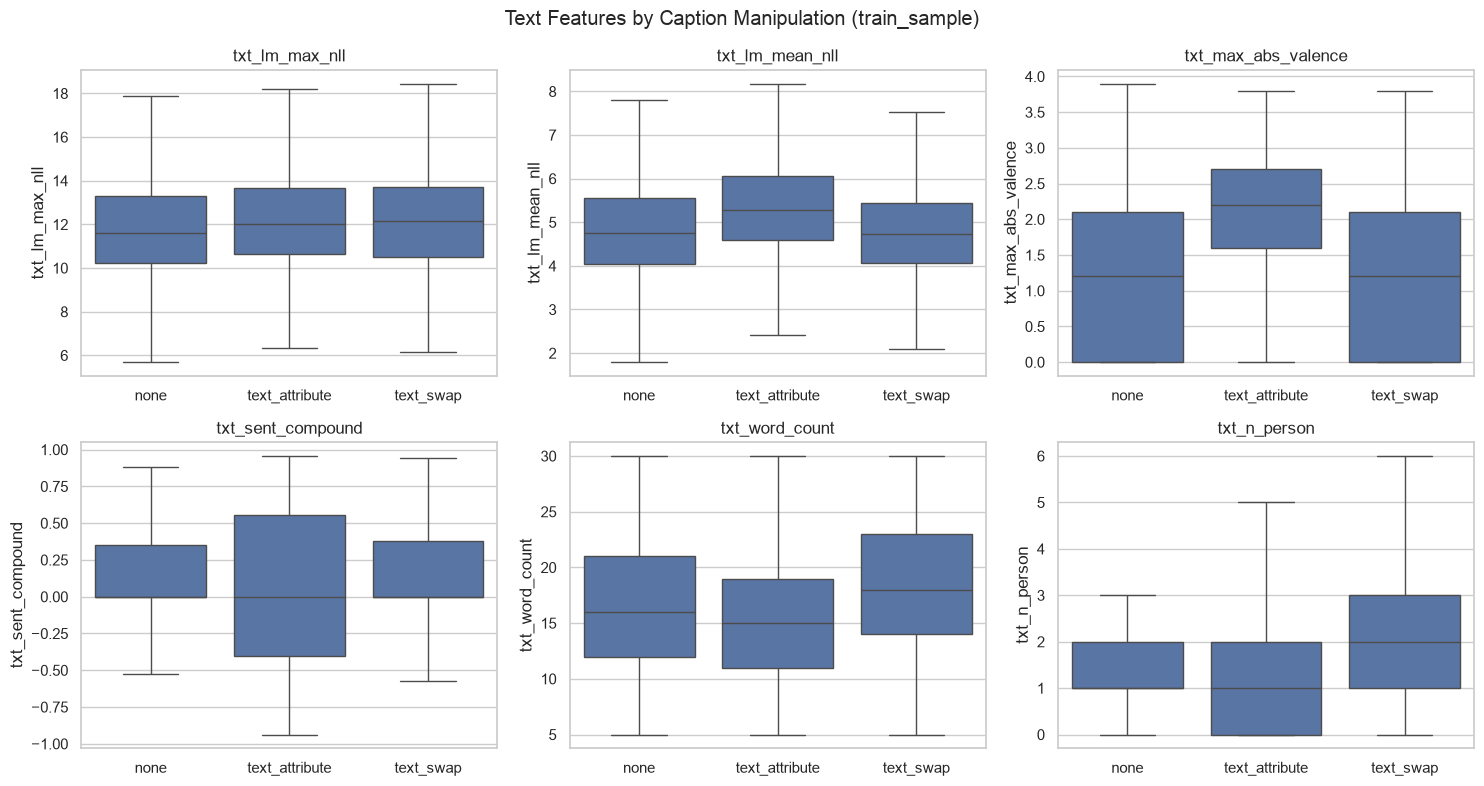

In [11]:
plot_cols = ["txt_lm_max_nll", "txt_lm_mean_nll", "txt_max_abs_valence", "txt_sent_compound", "txt_word_count", "txt_n_person"]
plot_df = data["train_sample"][["row_id", "text_manipulation"]].merge(text_features, on="row_id")

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, plot_cols):
    sns.boxplot(data=plot_df, x="text_manipulation", y=col, order=["none", "text_attribute", "text_swap"],
                showfliers=False, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Text Features by Caption Manipulation (train_sample)")
plt.tight_layout()
plt.show()

In [12]:
save_features(text_features, "text")

data/features/text_train_sample.parquet  (49943, 22)
data/features/text_validation.parquet  (22126, 22)
data/features/text_test.parquet  (50705, 22)


# Part 2: Image Features

Image features target the two face manipulations:
- **face_swap**: a face from another person blended into the photo, which can leave seams and a mismatch in noise or compression between the face and its surroundings
- **face_attribute**: the expression regenerated by a GAN (StyleCLIP, HFGI), which tends to leave the face smoother than real skin

All images are JPEGs. They are read straight from the Hugging Face zip archives with `src/images.py`. The feature code lives in `src/image_features.py`, so it can run in parallel worker processes.

## 2.1 Shortcut Check: Image Size and Compression

Before building pixel features, check that manipulated images were not saved differently from their originals (e.g. resized or re-saved at another JPEG quality). If they were, a model could detect fakes from file properties alone, which would not carry over to real-world images. We compare each manipulated image with the original image from the same article.

In [13]:
from src.images import load_image

orig_rows = data["train_sample"][data["train_sample"]["fake_cls"] == "orig"].drop_duplicates("id")
check_ids = orig_rows["id"].sample(300, random_state=RANDOM_STATE)
check = data["train_sample"][
    data["train_sample"]["id"].isin(check_ids)
    & ((data["train_sample"]["fake_cls"] == "orig") | (data["train_sample"]["image_fake"] == 1))
].drop_duplicates("image")


def file_properties(image_path):
    image = load_image(image_path, convert=False)
    return {"size": image.size, "jpeg_quant_table": tuple(image.quantization[0])}


props = pd.DataFrame([file_properties(p) for p in check["image"]], index=check["image"].values)
check = check.join(props, on="image")

originals = check[check["fake_cls"] == "orig"].set_index("id")
fakes = check[check["image_fake"] == 1].copy()
fakes["same_size_as_original"] = fakes["size"] == fakes["id"].map(originals["size"])
fakes["same_jpeg_quality_as_original"] = fakes["jpeg_quant_table"] == fakes["id"].map(originals["jpeg_quant_table"])
fakes.groupby("image_source")[["same_size_as_original", "same_jpeg_quality_as_original"]].mean()

,same_size_as_original,same_jpeg_quality_as_original
image_source,,
manipulation/HFGI,1.0,1.0
manipulation/StyleCLIP,1.0,1.0
manipulation/infoswap,1.0,1.0
manipulation/simswap,1.0,1.0


Every manipulated image keeps exactly the same size and JPEG quantisation table as its original, so the file properties do not give the label away. Image size still varies by publisher (BBC images are larger), so it is kept as a weak feature, and its AUC is checked below.

## 2.2 What the Forensic Maps Look Like

For each image we compute three per-pixel maps:
- **ELA (Error Level Analysis)**: re-save the image as JPEG (quality 90) and measure how much each pixel changes. Regions that were pasted in or regenerated often compress differently from the rest.
- **Laplacian residual**: a high-pass filter that keeps only sharp local changes, e.g. blending seams, or the lack of fine skin texture in generated faces.
- **Noise residual**: the image minus a median-filtered copy, i.e. the sensor and compression noise left once content is removed. A face from another source often carries a different noise level.

Below: an original and its face-swapped version from the same article. Red is the manipulated face, blue the other detected faces.

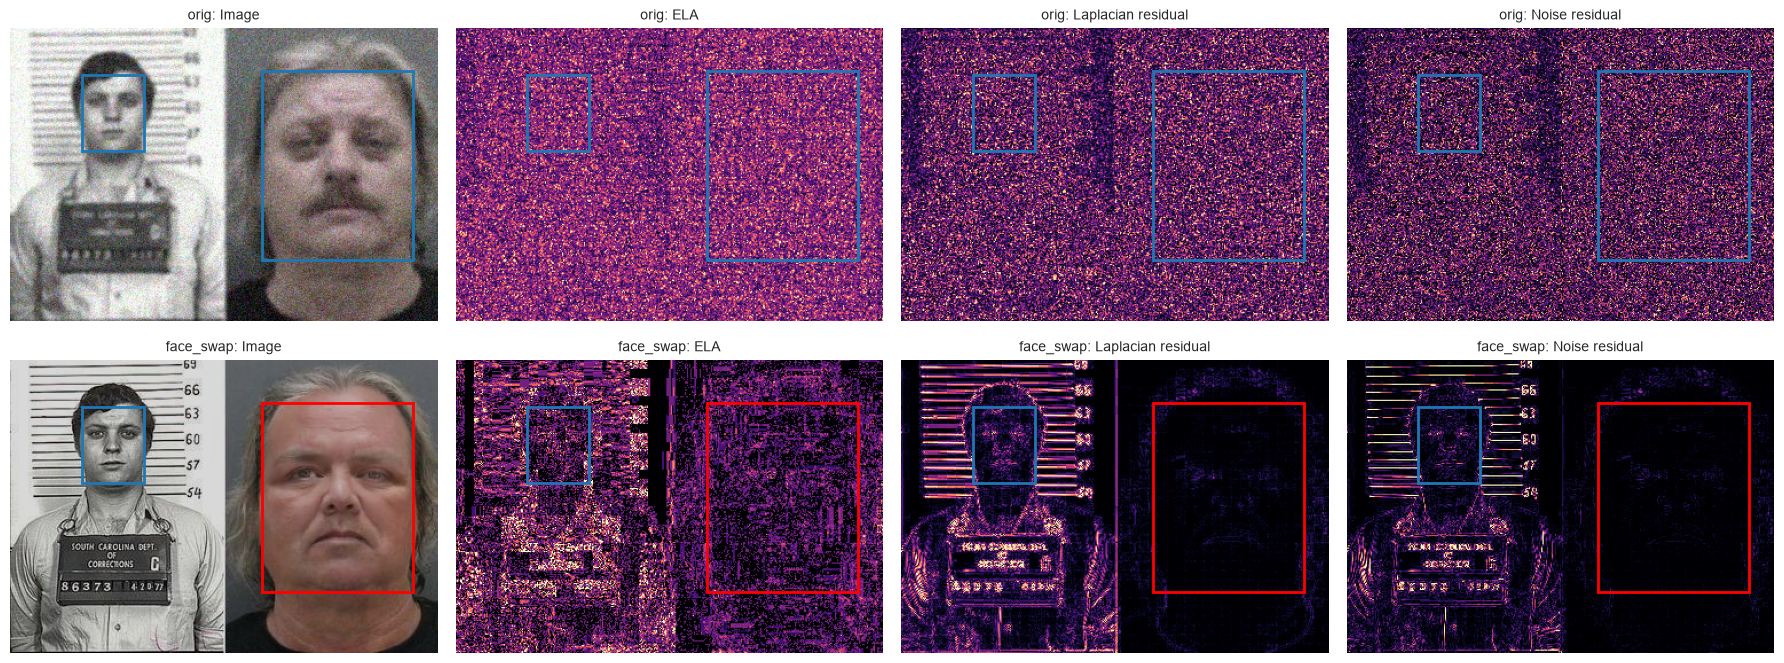

In [14]:
from matplotlib.patches import Rectangle
from src.image_features import forensic_maps

swap_row = data["train_sample"][data["train_sample"]["fake_cls"] == "face_swap"].sample(1, random_state=7).iloc[0]
orig_row = data["train_sample"][(data["train_sample"]["id"] == swap_row["id"]) & (data["train_sample"]["fake_cls"] == "orig")].iloc[0]

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax_row, row in zip(axes, [orig_row, swap_row]):
    image = load_image(row["image"])
    maps = forensic_maps(image)
    panels = [("Image", np.asarray(image)), ("ELA", maps["ela"]), ("Laplacian residual", maps["lap"]), ("Noise residual", maps["noise"])]
    for ax, (title, panel) in zip(ax_row, panels):
        ax.imshow(panel, cmap=None if title == "Image" else "magma",
                  vmax=None if title == "Image" else np.percentile(panel, 99))
        for box in row["mtcnn_boxes"]:
            is_fake_box = len(row["fake_image_box"]) and list(box) == list(row["fake_image_box"])
            ax.add_patch(Rectangle((box[0], box[1]), box[2] - box[0], box[3] - box[1], fill=False,
                                   edgecolor="red" if is_fake_box else "tab:blue", linewidth=2))
        ax.set_title(f"{row['fake_cls']}: {title}", fontsize=10)
        ax.axis("off")
plt.tight_layout()
plt.show()

## 2.3 Per-Face Features

For **every** detected face we measure the mean of each map inside the face box, and its ratio to a ring of pixels around the face (the box enlarged by 50% on each side, minus the face). The ratio compares the face with its own surroundings, which cancels out differences between photos (lighting, overall compression).

The edited face is the largest face only about 2/3 of the time, so each measurement is summarised across all faces in the image:
- `_max`, `_min`, `_mean` across faces, and `_largest` for the largest face
- `_spread` (ratios only): the gap between the most and least extreme face, on a log scale. Every image has at least 2 faces, so one edited face should stand out from the untouched faces in the same photo.

Plus image-level values: width, height, number of faces, the mean of each map over the whole image, and the size of the faces relative to the image.

In [15]:
from concurrent.futures import ProcessPoolExecutor
from src.image_features import image_features_safe

# Text-only fakes reuse the original image, so compute once per distinct image
images = all_rows.drop_duplicates("image")[["image", "mtcnn_boxes"]]
items = [(path, [[int(v) for v in box] for box in boxes]) for path, boxes in zip(images["image"], images["mtcnn_boxes"])]
print(f"{len(items):,} distinct images")

N_WORKERS = max(1, (os.cpu_count() or 2) - 2)
start = time.time()
with ProcessPoolExecutor(N_WORKERS) as pool:
    image_results = pd.DataFrame(pool.map(image_features_safe, items, chunksize=64))
print(f"{N_WORKERS} workers: {time.time() - start:.0f}s")

errors = image_results["error"].notna()
print("Images that failed:", int(errors.sum()))
assert not errors.any(), image_results.loc[errors, ["image", "error"]].head()

110,030 distinct images


10 workers: 421s
Images that failed: 0


In [16]:
image_features = (
    all_rows[["row_id", "image"]]
    .merge(image_results.drop(columns="error"), on="image", how="left")
    .drop(columns="image")
)
print(image_features.shape)
image_features.drop(columns="row_id").describe().T.round(3)

(122774, 36)


,count,mean,std,min,25%,50%,75%,max
img_width,122774.0,449.267,166.043,180.000,384.000,426.000,426.000,5353.000
img_height,122774.0,289.781,104.940,180.000,256.000,256.000,261.000,3958.000
img_n_faces,122774.0,2.673,0.934,2.000,2.000,2.000,3.000,5.000
img_ela_mean,122774.0,1.605,1.327,0.019,0.754,1.037,1.792,5.329
img_lap_mean,122774.0,16.294,13.274,0.089,5.452,12.618,22.544,112.196
img_noise_mean,122774.0,3.023,2.695,0.005,0.927,2.189,4.187,25.972
img_face_area_max,122774.0,0.050,0.059,0.003,0.016,0.029,0.057,0.672
img_face_area_mean,122774.0,0.038,0.046,0.002,0.012,0.022,0.043,0.633
img_ela_face_max,122774.0,2.018,1.333,0.207,1.075,1.436,2.592,5.967
img_ela_face_min,122774.0,1.731,1.331,0.089,0.865,1.135,2.075,5.413


## 2.4 Check and Save

In [17]:
image_auc = pd.concat(
    [univariate_auc(image_features, "image_fake"), univariate_auc(image_features, "is_fake")], axis=1
).round(3)
image_auc.head(20)

,AUC vs image_fake,AUC vs is_fake
img_ela_face_largest,0.375,0.400
img_ela_face_mean,0.382,0.404
img_ela_face_min,0.382,0.404
img_ela_face_max,0.386,0.408
img_ela_mean,0.394,0.411
img_noise_ratio_largest,0.410,0.433
img_lap_ratio_largest,0.417,0.436
img_noise_ratio_mean,0.427,0.447
img_noise_ratio_min,0.427,0.445
img_lap_ratio_mean,0.435,0.450


In [18]:
image_labels = data["train_sample"][["row_id", "image_manipulation"]]


def auc_vs_untouched(features, manipulation):
    subset = image_labels[image_labels["image_manipulation"].isin(["none", manipulation])]
    subset = subset.assign(target=(subset["image_manipulation"] == manipulation).astype(int))
    return univariate_auc(features, "target", label_df=subset)["AUC vs target"].rename(manipulation)


image_by_type = pd.concat(
    [auc_vs_untouched(image_features, m) for m in ["face_swap", "face_attribute"]], axis=1
).round(3)
image_by_type.sort_values("face_swap", key=lambda s: (s - 0.5).abs(), ascending=False).head(15)

,face_swap,face_attribute
img_ela_face_largest,0.396,0.350
img_ela_face_min,0.397,0.364
img_ela_face_mean,0.398,0.362
img_ela_face_max,0.403,0.366
img_ela_mean,0.406,0.380
img_noise_ratio_largest,0.407,0.413
img_lap_ratio_largest,0.413,0.423
img_noise_ratio_min,0.419,0.436
img_noise_ratio_mean,0.420,0.434
img_lap_ratio_mean,0.425,0.446


## 2.5 Shortcut Check: Does Each Feature Work for Every Publisher?

The originals come from four publishers. If a feature separates real from fake for only one publisher, it is more likely picking up how that publisher's images were processed when the dataset was built than the manipulation itself. Manipulated images carry no publisher in their path, so each fake is assigned the publisher of its article's original.

In [19]:
image_rows = data["train_sample"][["row_id", "id", "fake_cls", "image", "image_fake", "image_source"]].merge(image_features, on="row_id")
image_rows = image_rows.drop_duplicates("image")
publisher = image_rows[image_rows["fake_cls"] == "orig"].set_index("id")["image_source"].str.removeprefix("origin/")
image_rows["publisher"] = image_rows["id"].map(publisher)
image_rows = image_rows.dropna(subset=["publisher"])

img_cols = [c for c in image_features.columns if c.startswith("img_")]
by_publisher = pd.DataFrame({
    pub: {c: roc_auc_score(g["image_fake"], g[c]) for c in img_cols}
    for pub, g in image_rows.groupby("publisher")
})
by_publisher["all"] = [roc_auc_score(image_rows["image_fake"], image_rows[c]) for c in img_cols]
by_publisher.round(3).sort_values("all", key=lambda s: (s - 0.5).abs(), ascending=False).head(15)

,bbc,guardian,usa_today,washington_post,all
img_ela_face_largest,0.479,0.271,0.477,0.481,0.377
img_ela_face_min,0.473,0.285,0.477,0.477,0.383
img_ela_face_mean,0.491,0.275,0.480,0.484,0.383
img_ela_face_max,0.503,0.278,0.484,0.493,0.387
img_ela_mean,0.500,0.290,0.485,0.496,0.393
img_noise_ratio_largest,0.407,0.409,0.438,0.431,0.415
img_lap_ratio_largest,0.420,0.413,0.440,0.429,0.420
img_noise_ratio_min,0.421,0.425,0.448,0.446,0.430
img_noise_ratio_mean,0.423,0.427,0.451,0.452,0.432
img_lap_ratio_min,0.435,0.430,0.449,0.448,0.436


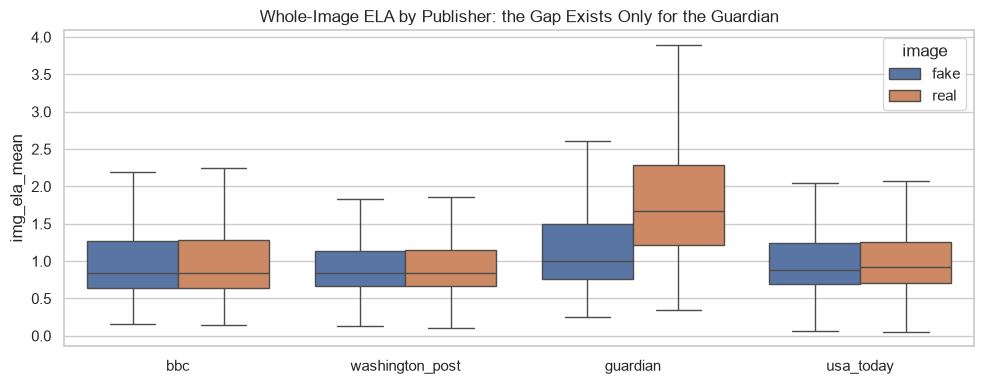

In [20]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=image_rows, x="publisher", y="img_ela_mean", hue=image_rows["image_fake"].map({0: "real", 1: "fake"}),
            showfliers=False, ax=ax)
ax.set_title("Whole-Image ELA by Publisher: the Gap Exists Only for the Guardian")
ax.set_xlabel("")
ax.legend(title="image")
plt.tight_layout()
plt.show()

**Absolute ELA is a dataset shortcut.** `img_ela_mean` and the `img_ela_face_*` features separate real from fake only for the Guardian (AUC about 0.29, i.e. 0.71 inverted) and are close to 0.5 for the other three publishers. Fakes made from Guardian photos appear to have been re-compressed by the dataset pipeline while the Guardian originals were not, so these features detect "this file was re-saved" rather than "this face was edited". They are listed in `src/feature_sets.py` as `ARTIFACT_FEATURES` and excluded from the main models.

**The face-vs-surroundings ratios are a genuine signal.** `img_noise_ratio_*` and `img_lap_ratio_*` behave the same for every publisher (AUC about 0.41 to 0.45): the edited face has less fine detail and noise than the pixels around it, consistent with generated or blended faces being smoother. On their own they are weak, so they are expected to help in combination with CLIP and CNN features rather than alone.

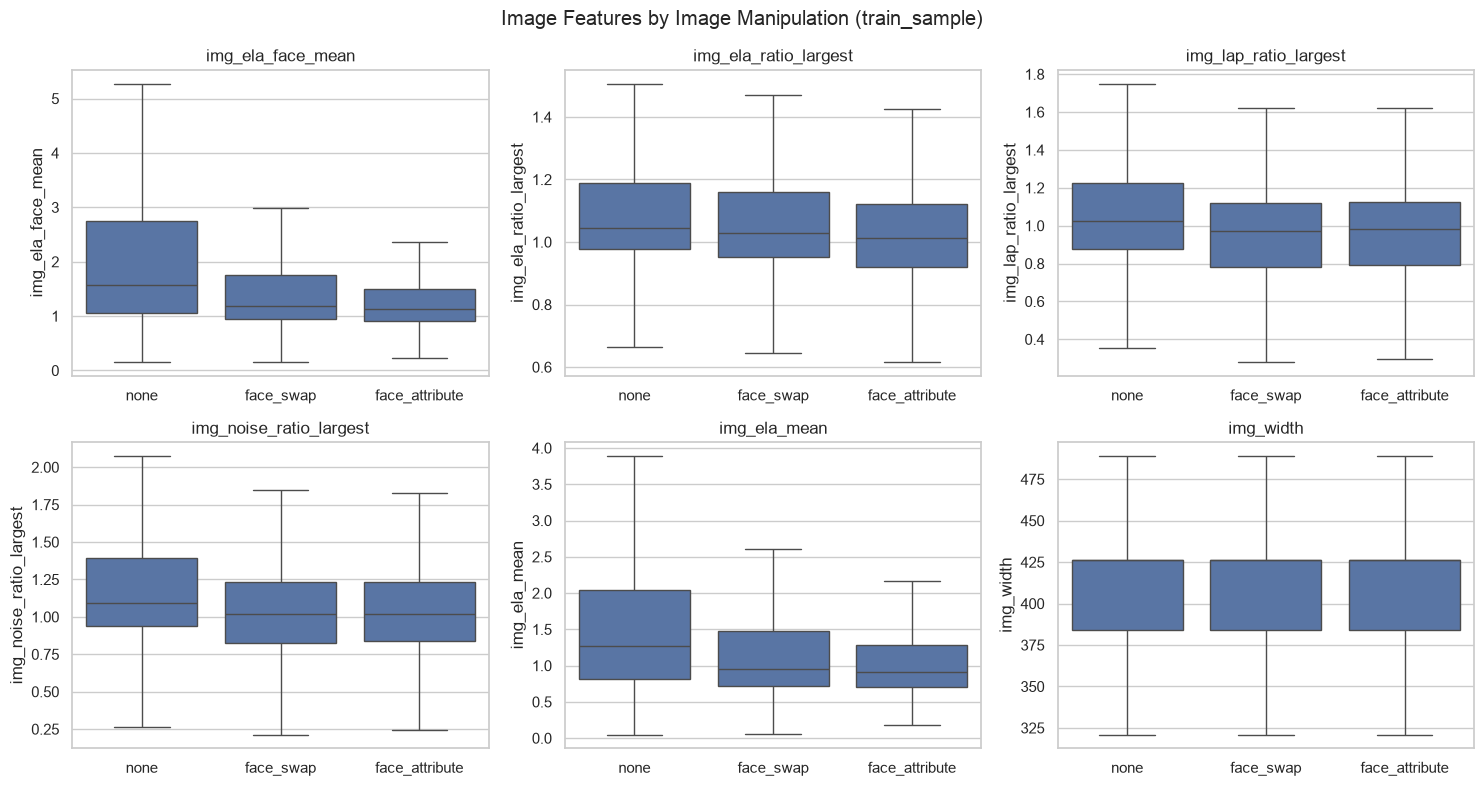

In [21]:
plot_cols = ["img_ela_face_mean", "img_ela_ratio_largest", "img_lap_ratio_largest",
             "img_noise_ratio_largest", "img_ela_mean", "img_width"]
plot_df = data["train_sample"][["row_id", "image_manipulation"]].merge(image_features, on="row_id")

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, plot_cols):
    sns.boxplot(data=plot_df, x="image_manipulation", y=col, order=["none", "face_swap", "face_attribute"],
                showfliers=False, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Image Features by Image Manipulation (train_sample)")
plt.tight_layout()
plt.show()

In [22]:
save_features(image_features, "image")

data/features/image_train_sample.parquet  (49943, 36)
data/features/image_validation.parquet  (22126, 36)
data/features/image_test.parquet  (50705, 36)


# Summary

**Saved feature groups** (`data/features/<group>_<split>.parquet`, joined on `row_id`):

| Group | Columns | What it targets |
|---|---|---|
| `text` | 21 `txt_*` features: structure, named entities, VADER sentiment, GPT-2 surprise | text_attribute (sentiment flips, odd phrasing) |
| `image` | 35 `img_*` features: image size, ELA / Laplacian / noise statistics per face and relative to each face's surroundings | face_swap, face_attribute |

**What the features show (train_sample, single-feature AUC)**
- **text_attribute** is the most detectable caption edit: strongest word valence (AUC 0.72), VADER neutral share (0.26, i.e. 0.74 inverted) and GPT-2 mean surprise (0.63). Flipped words are more emotionally charged and make captions less fluent.
- **text_swap** is barely detectable from text alone (best: number of people mentioned, 0.69; length, 0.59). As expected, it needs image-caption consistency features (CLIP).
- **Image features** are weak individually (best genuine ones about 0.41 to 0.45, i.e. 0.55 to 0.59 inverted). Edited faces are smoother than their surroundings.

**Shortcuts found and excluded** (`src/feature_sets.ARTIFACT_FEATURES`)
- Absolute ELA works only for Guardian images, due to re-compression of their fakes during dataset construction.
- Caption length reflects how swapped captions were chosen.
- Checked and **not** a shortcut: image size and JPEG quality (identical between each fake and its original), and the random noise and blur perturbations (equally common in real and fake images).

**Adding features later:** add a new subsection that saves a new group with `save_features(df, "<group>")`, then join it in the modelling notebook on `row_id`.